In [1]:
import os
import json
import numpy as np
import pandas as pd
import scipy.io
import anndata as ad
from scipy.sparse import lil_matrix, issparse
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA, NMF
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from umap import UMAP

import torch
import torch.nn as nn
import torch.nn.functional as F
import pyliger

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/h5sparse/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/home/sc5625/.local/share/m

## Define helper functions

In [2]:
def as_dense(x):
    return x.toarray() if issparse(x) else np.asarray(x)

def jaccard(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    denom = np.logical_or(a, b).sum()
    return 0.0 if denom == 0 else np.logical_and(a, b).sum() / denom

def top_support_mask(vec, frac=0.05):
    vec = np.abs(np.asarray(vec).ravel())
    k = max(1, int(np.ceil(frac * vec.size)))
    mask = np.zeros(vec.size, dtype=bool)
    mask[np.argpartition(vec, -k)[-k:]] = True
    return mask

def edge_overlap_metrics(A_pred, A_ref, frac=0.05):
    pred = top_support_mask(A_pred, frac=frac)
    ref = top_support_mask(A_ref, frac=frac)
    tp = np.logical_and(pred, ref).sum()
    fp = pred.sum() - tp
    fn = ref.sum() - tp
    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    jac = tp / (pred.sum() + ref.sum() - tp + 1e-8)
    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "jaccard": float(jac),
        "tp": int(tp),
        "pred_edges": int(pred.sum()),
        "ref_edges": int(ref.sum()),
    }

def mean_axis_jaccard(A_pred, A_ref, axis=0, frac=0.1):
    scores = []
    if axis == 0:  # per TF column
        for j in range(A_ref.shape[1]):
            p = top_support_mask(A_pred[:, j], frac=frac)
            r = top_support_mask(A_ref[:, j], frac=frac)
            scores.append(jaccard(p, r))
    else:  # per gene row
        for i in range(A_ref.shape[0]):
            p = top_support_mask(A_pred[i, :], frac=frac)
            r = top_support_mask(A_ref[i, :], frac=frac)
            scores.append(jaccard(p, r))
    return float(np.mean(scores)) if scores else 0.0

def module_sets_from_nmf(W, H, top_genes=25, top_tfs=15):
    # W: genes x r, H: r x tfs
    modules = []
    for k in range(W.shape[1]):
        g_idx = np.argsort(-W[:, k])[:top_genes]
        t_idx = np.argsort(-H[k, :])[:top_tfs]
        modules.append((set(g_idx.tolist()), set(t_idx.tolist())))
    return modules

def module_similarity(m1, m2):
    g1, t1 = m1
    g2, t2 = m2
    return 0.5 * jaccard(g1, g2) + 0.5 * jaccard(t1, t2)

def match_module_sets(ref_modules, cur_modules):
    S = np.array([[module_similarity(r, c) for c in cur_modules] for r in ref_modules], dtype=float)
    row_ind, col_ind = linear_sum_assignment(-S)
    matched = S[row_ind, col_ind]
    return {
        "mean_conservation": float(np.mean(matched)),
        "std_conservation": float(np.std(matched)),
        "matched_scores": matched,
        "similarity_matrix": S,
    }

def pseudotime_arrow_agreement(X_space, V_pred, pseudotime, k=30):
    """
    For each cell, find the nearest neighbor with slightly larger pseudotime
    among local neighbors, and compare that arrow with predicted velocity.
    Returns mean cosine agreement and fraction positive.
    """
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(X_space))).fit(X_space)
    idx = nn.kneighbors(X_space, return_distance=False)[:, 1:]

    arrows = np.zeros_like(X_space, dtype=float)
    valid = np.zeros(len(X_space), dtype=bool)

    for i in range(len(X_space)):
        nbrs = idx[i]
        later = nbrs[pseudotime[nbrs] > pseudotime[i]]
        if later.size == 0:
            continue
        j = later[np.argmin(pseudotime[later] - pseudotime[i])]
        arrows[i] = X_space[j] - X_space[i]
        valid[i] = True

    if valid.sum() == 0:
        return {"mean_cosine": np.nan, "fraction_positive": np.nan, "n_valid": 0}

    Vn = normalize(V_pred[valid], norm="l2", axis=1)
    An = normalize(arrows[valid], norm="l2", axis=1)
    cos = np.sum(Vn * An, axis=1)

    return {
        "mean_cosine": float(np.mean(cos)),
        "fraction_positive": float(np.mean(cos > 0)),
        "n_valid": int(valid.sum()),
        "cosines": cos,
    }

## Step 1: Load RNA and define model universe (genes, TFs)

In [3]:
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"
os.makedirs("uv_leading_fixed", exist_ok=True)

rna_adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
gene_names_all = np.array(rna_adata.var_names.astype(str))
gene_to_idx_full = {g: i for i, g in enumerate(gene_names_all)}
X_full = as_dense(rna_adata.X).astype(np.float32)

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()
motif_tf_names = open(f"{BASE}/tf_names.txt").read().strip().split()
motif_tf_to_idx = {t: i for i, t in enumerate(motif_tf_names)}

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")
peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak_to_idx = {p: i for i, p in enumerate(peaks)}

genes_in_peaks = set(peak_gene["gene"].astype(str).unique())
A_genes = np.array([g for g in gene_names_all if g in genes_in_peaks], dtype=str)

# IMPORTANT: TFs must exist as genes in the RNA matrix for X_TF
A_tfs = np.array([t for t in motif_tf_names if t in gene_to_idx_full], dtype=str)

print(f"A_genes: {len(A_genes)}, A_tfs: {len(A_tfs)}")

gene_idx = np.array([gene_to_idx_full[g] for g in A_genes], dtype=int)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)

X = X_full[:, gene_idx]      # cells x genes
X_TF = X_full[:, tf_idx]     # cells x TFs
sub_g2i = {g: i for i, g in enumerate(A_genes)}

A_genes: 11483, A_tfs: 277


## Step 2: Build M (gene x TF accessibility mask)

In [4]:
P = len(peaks)
G = len(A_genes)

peak_gene_mat = lil_matrix((P, G), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = str(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx and g in sub_g2i:
        peak_gene_mat[peak_to_idx[p], sub_g2i[g]] = 1.0
peak_gene_mat = peak_gene_mat.tocsr()

M_full = (peak_gene_mat.T @ peak_tf)
M_full = (M_full > 0).astype(np.float32)

# align M columns to the TFs actually present in RNA
A_tfs = np.array([t for t in A_tfs if t in motif_tf_to_idx], dtype=str)
tf_idx = np.array([gene_to_idx_full[t] for t in A_tfs], dtype=int)
tf_col = np.array([motif_tf_to_idx[t] for t in A_tfs], dtype=int)

X_TF = X_full[:, tf_idx]  # refresh after final TF filtering
M = M_full[:, tf_col].toarray().astype(np.float32)

assert M.shape == (len(A_genes), len(A_tfs))

## Step 3: ATAC gene activity and gene accessibility prior

In [5]:
print("Loading ATAC raw matrix...")
atac_raw = scipy.io.mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.T.astype(np.float32)   # cells x peaks

peaks_atac = pd.read_csv(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz", sep="\t")
peak_names = peaks_atac["Feature"].str.replace("_", ":", n=1).str.replace("_", "-", n=1).tolist()
peak_to_idx_atac = {p: i for i, p in enumerate(peak_names)}

def fix_peak(p):
    return str(p).replace("-", ":", 1)

P2 = len(peak_names)
G2 = len(A_genes)

peak_gene_mat_atac = lil_matrix((P2, G2), dtype=np.float32)
for _, row in peak_gene.iterrows():
    p = fix_peak(row["peak"])
    g = str(row["gene"])
    if p in peak_to_idx_atac and g in sub_g2i:
        peak_gene_mat_atac[peak_to_idx_atac[p], sub_g2i[g]] = 1.0
peak_gene_mat_atac = peak_gene_mat_atac.tocsr()

gene_activity = atac_X @ peak_gene_mat_atac   # cells x genes
gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = as_dense(gene_activity).astype(np.float32)
gene_activity = np.log1p(gene_activity)

cell_idx = np.arange(X.shape[0])
atac_X = as_dense(atac_X)[cell_idx]
gene_activity = gene_activity[cell_idx]

gene_access = gene_activity.mean(axis=0)
gene_access = (gene_access - gene_access.min()) / (gene_access.max() - gene_access.min() + 1e-8)
gene_access_t = torch.tensor(gene_access, dtype=torch.float32)

Loading ATAC raw matrix...


## Step 4: TF Access Prior

In [6]:
# ── imports ──────────────────────────────────────────────────────────────────
import os, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
 
os.makedirs("bert_grn_out", exist_ok=True)

In [7]:
def build_tf_access_prior(gene_activity: np.ndarray,
                           A_tfs: np.ndarray,
                           gene_to_idx_full: dict,
                           gene_names_all: np.ndarray) -> np.ndarray:
    """
    Returns TF_access: (T,) float32 — population-mean chromatin accessibility
    for each TF locus, derived from the ATAC gene-activity matrix.
    """
    T = len(A_tfs)
    tf_access = np.zeros(T, dtype=np.float32)
    for i, tf in enumerate(A_tfs):
        if tf in gene_to_idx_full:
            g = gene_to_idx_full[tf]          # index in full gene list
            # find column in gene_activity that corresponds to this gene
            # gene_activity columns align with A_genes (from Step 2/3)
            # We need the sub-index; if tf is in A_genes use sub_g2i
            # otherwise fall back to 0
            if tf in sub_g2i:
                col = sub_g2i[tf]
                tf_access[i] = float(gene_activity[:, col].mean())
    # min-max normalise to [0, 1]
    lo, hi = tf_access.min(), tf_access.max()
    tf_access = (tf_access - lo) / (hi - lo + 1e-8)
    return tf_access
 
 
# ── call it (uses variables already in scope from earlier steps) ──────────
TF_access_prior = build_tf_access_prior(
    gene_activity, A_tfs, gene_to_idx_full, gene_names_all
)
TF_access_t = torch.tensor(TF_access_prior, dtype=torch.float32)  # (T,)
 
print(f"TF access prior: mean={TF_access_prior.mean():.3f}  "
      f"nonzero={np.mean(TF_access_prior > 0.05):.1%}")

TF access prior: mean=0.173  nonzero=76.9%


## Step 5: Define model

In [8]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import torch.nn as nn

def initialize_grn_dictionary_from_clusters(
    X: np.ndarray,          # (N, G) RNA
    V_dec2: np.ndarray,     # (N, 2) for clustering
    M: np.ndarray,          # (G, T) motif mask
    D: int,                 # number of atoms
    A_tfs: np.ndarray,
    sub_g2i: dict,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Returns:
      cluster_labels : (N,) int — which cluster each cell belongs to
      W_init         : (D, G, T) float32 — per-atom initial weights
    """
    # 1. Cluster in Decipher space (already a good low-dim representation)
    print(f"Clustering into {D} groups in Decipher space...")
    km = KMeans(n_clusters=D, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(V_dec2)
    
    # 2. For each cluster, find marker genes (high mean, low in others)
    W_init = np.zeros((D, X.shape[1], len(A_tfs)), dtype=np.float32)
    
    for d in range(D):
        in_mask  = cluster_labels == d
        out_mask = ~in_mask
        
        if in_mask.sum() < 3:
            continue
        
        # Mean expression inside vs outside this cluster
        mean_in  = X[in_mask].mean(axis=0)    # (G,)
        mean_out = X[out_mask].mean(axis=0)   # (G,)
        
        # Log fold change as a simple specificity score
        lfc = np.log1p(mean_in) - np.log1p(mean_out)  # (G,)
        
        # Initialize weights for this atom proportional to cluster-specific LFC
        # Only where motif mask allows (M > 0)
        for t_i in range(len(A_tfs)):
            col = M[:, t_i]                   # (G,) binary motif mask
            if col.sum() == 0:
                continue
            # Weight = LFC scaled to [-0.3, 0.3] within motif-allowed genes
            lfc_masked = lfc * col
            lfc_range  = np.abs(lfc_masked).max() + 1e-8
            W_init[d, :, t_i] = lfc_masked / lfc_range * 0.3
    
    print(f"Cluster sizes: {[int((cluster_labels==d).sum()) for d in range(D)]}")
    return cluster_labels, W_init


class GRNDictionary(nn.Module):
    def __init__(self, G: int, T: int, M: np.ndarray, D: int = 6):
        super().__init__()
        self.D = D
        self.G = G
        self.T = T
        
        self.W_raw = nn.Parameter(torch.zeros(D, G, T))
        
        M_t = torch.tensor(M, dtype=torch.float32)
        self.register_buffer("M", M_t)
        self.register_buffer("TF_access", torch.zeros(T))
    
    def init_from_clusters(self, W_init: np.ndarray):
        """Call this after construction to break symmetry."""
        with torch.no_grad():
            # atanh(x) is the inverse of tanh — so tanh(W_raw) = W_init
            W_clamped = np.clip(W_init, -0.95, 0.95)
            self.W_raw.copy_(torch.tensor(np.arctanh(W_clamped), dtype=torch.float32))
        print("GRN dictionary initialized from cluster LFC profiles.")
    
    @property
    def A_dict(self) -> torch.Tensor:
        return torch.tanh(self.W_raw) * self.M.unsqueeze(0)   # (D, G, T)
    
    def get_cell_grn(self, weights: torch.Tensor) -> torch.Tensor:
        """weights: (B, D) -> (B, G, T) per-cell mixed GRN"""
        return torch.einsum('bd,dgt->bgt', weights, self.A_dict)
    
    def predict_rna(self, X_TF: torch.Tensor, weights: torch.Tensor) -> torch.Tensor:
        """X_TF: (B,T), weights: (B,D) -> (B,G)"""
        A_cell = self.get_cell_grn(weights)                    # (B, G, T)
        return torch.bmm(X_TF.unsqueeze(1), 
                         A_cell.transpose(1, 2)).squeeze(1)    # (B, G)
    
    def get_effective_A(self, weights: torch.Tensor) -> torch.Tensor:
        """For a single cell or mean weights. weights: (D,) -> (G, T)"""
        return (weights[:, None, None] * self.A_dict).sum(dim=0)
    
    def sparsity_loss(self) -> torch.Tensor:
        return torch.abs(self.A_dict).mean()
    
    def diversity_loss(self) -> torch.Tensor:
        """
        Repel GRN atoms from each other in function space.
        We measure similarity by the CORRELATION of their outputs
        on the training set, not just parameter similarity.
        """
        A_flat = self.A_dict.reshape(self.D, -1)      # (D, G*T)
        A_norm = F.normalize(A_flat, dim=1)
        gram   = A_norm @ A_norm.T                    # (D, D)
        # Penalize off-diagonal cosine similarity
        eye    = torch.eye(self.D, device=gram.device)
        return (gram * (1 - eye)).abs().mean()
    
    def tf_access_consistency_loss(self) -> torch.Tensor:
        closed = 1.0 - self.TF_access.clamp(0, 1)
        return (torch.abs(self.A_dict) * 
                closed.unsqueeze(0).unsqueeze(0)).mean()
    
    def per_tf_norm_loss(self) -> torch.Tensor:
        col_norms = torch.norm(self.A_dict, dim=1)    # (D, T)
        target    = (self.M.sum(dim=0).clamp(min=1) ** 0.5) * 0.1
        return ((col_norms - target.unsqueeze(0)) ** 2).mean()

In [9]:
class CellStateEncoder(nn.Module):
    """
    Maps cell expression -> D-dim mixing weights.
    Warm-started so atom d initially activates for cluster d.
    """
    def __init__(self, G: int, D: int, hidden: int = 128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(G, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden // 2),
            nn.GELU(),
        )
        self.head = nn.Linear(hidden // 2, D)
        self.D = D
    
    def init_from_cluster_labels(
        self, 
        X: np.ndarray, 
        cluster_labels: np.ndarray,
        n_epochs: int = 30
    ):
        """
        Pre-train the encoder to predict cluster membership.
        This gives each atom a distinct spatial territory before
        GRN training begins.
        """
        print("Pre-training cell state encoder on cluster labels...")
        self.train()
        opt = torch.optim.Adam(self.parameters(), lr=1e-3)
        
        X_t  = torch.tensor(X, dtype=torch.float32)
        y_t  = torch.tensor(cluster_labels, dtype=torch.long)
        ds   = TensorDataset(X_t, y_t)
        dl   = DataLoader(ds, batch_size=256, shuffle=True)
        
        for ep in range(n_epochs):
            total = 0
            for xb, yb in dl:
                logits = self.head(self.encoder(xb))
                loss   = F.cross_entropy(logits, yb)
                opt.zero_grad(); loss.backward(); opt.step()
                total += loss.item()
            if ep % 10 == 0:
                print(f"  Encoder pre-train epoch {ep}: CE={total/len(dl):.3f}")
        
        print("Encoder pre-training complete.")
    
    def forward(self, rna: torch.Tensor, 
                temperature: float = 1.0) -> torch.Tensor:
        h      = self.encoder(rna)
        logits = self.head(h)
        return F.softmax(logits / temperature, dim=-1)   # (B, D)
    
    def get_hard_assignments(self, rna: torch.Tensor) -> torch.Tensor:
        """Argmax — use for evaluation/visualization only."""
        with torch.no_grad():
            return self.forward(rna).argmax(dim=1)

## Step 7: BERT Task

In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 7  –  Masked Reconstruction (BERT task)
# ═══════════════════════════════════════════════════════════════════════════
#
# Algorithm:
#   1. For each cell i, sample a binary mask m_i ∈ {0,1}^G  (fraction p_mask)
#   2. Zero out the masked genes:  x_masked = x * (1 - m)
#   3. Reconstruct using GRN:      x_hat    = TF_expr @ A.T
#   4. Loss only on MASKED positions: MSE(x_hat[m], x[m])
#
# Why this works:
#   If the GRN weights are wrong, x_hat will be random and the loss is high.
#   The ONLY way to minimise is to make A[g, :] point in the direction of the
#   true regulatory relationship between TFs and gene g — learned from the
#   *structure* of co-variation across cells, not from a labelled target.
 
def masked_reconstruction_loss(grn, cell_encoder, rna_batch, tf_batch,
                                tf_indices_in_G, mask_frac=0.40,
                                temperature=1.0):
    B, G = rna_batch.shape
    device = rna_batch.device
    
    mask = torch.rand(B, G, device=device) < mask_frac
    
    tf_input_masked = tf_batch.clone()
    batch_idx = torch.arange(B, device=device).unsqueeze(1)
    tf_input_masked[batch_idx, 
                    torch.arange(len(tf_indices_in_G), device=device)] *= \
        (~mask[batch_idx, tf_indices_in_G]).float()
    
    mix_weights = cell_encoder(rna_batch, temperature=temperature)
    rna_pred    = grn.predict_rna(tf_input_masked, mix_weights)
    
    if mask.sum() == 0:
        return rna_pred.mean() * 0.0
    return F.mse_loss(rna_pred[mask], rna_batch[mask])

In [11]:
# Run this once before starting training
# Find the local index of each TF within the A_genes list
tf_indices_in_G = []
for tf_name in A_tfs:
    if tf_name in sub_g2i:
        tf_indices_in_G.append(sub_g2i[tf_name])
    else:
        # This shouldn't happen based on your A_tfs filtering, but for safety:
        tf_indices_in_G.append(-1) 

tf_indices_in_G = torch.tensor(tf_indices_in_G, dtype=torch.long)

## Step 8: Velocity Head

In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 9  –  Velocity Head (adapted for dictionary GRN)
# ═══════════════════════════════════════════════════════════════════════════
#
# Velocity should be a learned transformation of the DISEQUILIBRIUM
# signal (steady_state - rna).
#
# For the dictionary model, the steady state is per-cell:
#   steady_i = sum_d  w_{i,d} * A_d @ tf_i
# where w_i are the softmax mixing weights for cell i.
# The disequilibrium is thus also per-cell, which makes the velocity
# automatically cell-state-dependent without needing the ODE.
 
import torch.nn as nn
 
class DictVelocityHead(nn.Module):
    """
    Velocity head adapted for the dictionary GRN.
    
    Takes the per-cell disequilibrium signal (mixed_steady - rna) and
    learns a nonlinear transformation of it into velocity.
    
    This is identical in spirit to VelocityHead in the working model,
    but receives the mixed steady state instead of the global one.
    """
    def __init__(self, G: int, hidden: int = 512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(G, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Linear(hidden, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Linear(hidden, G)
        )
        self.scale = nn.Parameter(torch.ones(1) * 0.1)
    
    def forward(self, rna: torch.Tensor, grn, cell_encoder,
                tf: torch.Tensor, temperature: float = 1.0) -> torch.Tensor:
        # Per-cell mixed steady state
        with torch.set_grad_enabled(grn.W_raw.requires_grad or self.training):
            mix_weights = cell_encoder(rna, temperature=temperature)
            steady = grn.predict_rna(tf, mix_weights)          # (B, G)
        
        # Disequilibrium signal — the "direction" the cell should move
        disequil = steady - rna                                # (B, G)
        
        # Learned velocity from disequilibrium
        v_pred = self.net(disequil) * self.scale               # (B, G)
        return v_pred
 

## Step 9 & 10: Velocity Self-Consistency Loss & ATAC Directional Prior

In [20]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 10  –  Velocity Self-Consistency Loss (restored from working model)
# ═══════════════════════════════════════════════════════════════════════════
#
# Math:
#   disequil = steady - rna
#   cos_loss = mean(1 - cosine_sim(v_pred, disequil))
#   mag_loss = mean(|v_pred| - |disequil|)
#   loss = cos_loss + 0.1 * mag_loss
 
def velocity_consistency_loss(velocity, rna, steady_state):
    disequil = steady_state - rna
    
    # 1. Cosine alignment: velocity should point toward steady state
    v_norm = F.normalize(velocity, dim=1)
    d_norm = F.normalize(disequil, dim=1)
    cosine_sim = (v_norm * d_norm).sum(dim=1)
    
    # 2. Magnitude guard: don't let velocity collapse to zero
    mag_loss = torch.abs(velocity.norm(dim=1) - disequil.norm(dim=1).detach()).mean()
    
    return (1.0 - cosine_sim).mean() + 0.1 * mag_loss
 
 
def atac_direction_loss(velocity, gene_access_batch):
    closed = 1.0 - gene_access_batch.to(velocity.device)
    return (closed * torch.relu(velocity)).mean()
 
 
def atac_direction_loss_asymmetric(velocity, gene_access_batch):
    closed = 1.0 - gene_access_batch.to(velocity.device)
    growth_penalty  = torch.relu(velocity)  * closed * 2.0
    shrink_penalty  = torch.relu(-velocity) * (1.0 - closed) * 0.5
    return (growth_penalty + shrink_penalty).mean()
 
 
def velocity_smoothness_loss(velocity, batch_indices, neighbor_lookup, batch_size=256):
    B = velocity.shape[0]
    neighbor_ids = neighbor_lookup[batch_indices]
    mask = neighbor_ids.unsqueeze(-1) == batch_indices.view(1, 1, -1)
    has_neighbor, _, local_idx = mask.nonzero(as_tuple=True)
    if len(local_idx) < 2:
        return velocity.pow(2).mean() * 1e-4
    return F.mse_loss(velocity[has_neighbor], velocity[local_idx])
 
 
def density_gradient_loss(velocity, batch_idx, V_dec2):
    v_mag = velocity.norm(dim=1)
    return torch.relu(0.1 - v_mag).mean()
 
 
def divergence_loss(velocity, batch_idx, rna_b, neighbor_indices_t, X_t):
    neigh_idx    = neighbor_indices_t[batch_idx]
    X_neighbors  = X_t[neigh_idx]
    displacements = X_neighbors - rna_b.unsqueeze(1)
    centroid_disp = displacements.mean(dim=1)
    v_unit = F.normalize(velocity,       dim=1)
    c_unit = F.normalize(centroid_disp,  dim=1)
    sink_score = (v_unit * c_unit).sum(dim=-1)
    return torch.relu(sink_score).mean()

def atac_rna_drift_loss(velocity, rna_batch, gene_access_batch,
                        gap_threshold=0.1, min_genes=50):
    device = velocity.device
 
    # Normalize RNA to [0, 1] per cell (same scale as gene_access)
    rna_min  = rna_batch.min(dim=1, keepdim=True).values
    rna_max  = rna_batch.max(dim=1, keepdim=True).values
    rna_norm = (rna_batch - rna_min) / (rna_max - rna_min + 1e-8)   # (B, G)
 
    ga = gene_access_batch.to(device)
 
    # ATAC–RNA gap: positive = chromatin open, RNA not yet there
    gap = ga - rna_norm                                               # (B, G)
 
    # Weight each gene by |gap|; zero out below threshold (noise)
    gap_mag = gap.abs()
    gap_weight = torch.where(gap_mag > gap_threshold,
                             gap_mag, torch.zeros_like(gap_mag))     # (B, G)
 
    # Skip cells with too few informative genes (already at equilibrium)
    active_genes = (gap_weight > 0).float().sum(dim=1)               # (B,)
    active_mask  = active_genes >= min_genes                         # (B,)
 
    if active_mask.sum() < 2:
        # All cells are near equilibrium — no gradient needed
        return velocity.new_zeros(1).squeeze()
 
    vel_active  = velocity[active_mask]                              # (L, G)
    gap_active  = gap[active_mask]                                   # (L, G)
    wgt_active  = gap_weight[active_mask]                            # (L, G)
 
    # Weighted cosine: align velocity with the gap direction
    # Numerator:   sum_g  w_g * v_g * gap_g  (weighted dot product)
    # Denominator: ||w * v|| * ||w * gap||
    wv  = wgt_active * vel_active                                    # (L, G)
    wg  = wgt_active * gap_active                                    # (L, G)
 
    num   = (wv * wg).sum(dim=1)                                     # (L,)
    denom = (wv.norm(dim=1) * wg.norm(dim=1) + 1e-8)                # (L,)
    cos   = num / denom                                               # (L,)
 
    # Cosine loss: 1 - cos (0 = perfect alignment, 2 = perfectly backward)
    return (1.0 - cos).mean()
 

## Step 10.5: Set Neighbors

In [14]:
NEIGHBOR_SPACE = "pca"   # always "pca" for this notebook
 
def build_neighbor_index(X, X_2d_vis, Z_pca_50, mode="pca", k=30):
    """
    mode = "pca"  → neighbors in top-30 PCA of log-normalized expression
    mode = "umap" → same as pca (UMAP coords not used for loss neighbors)
    """
    if mode in ("pca", "umap"):
        ref = Z_pca_50          # (N, 30) — stable high-dim space
    else:
        raise ValueError(f"Unknown NEIGHBOR_SPACE={mode}")
    nbrs = NearestNeighbors(n_neighbors=k).fit(ref)
    _, neighbor_indices = nbrs.kneighbors(ref)
    return torch.tensor(neighbor_indices, dtype=torch.long)

## Step 10.75: GIF Maker

In [15]:
import io, os
import numpy as np
import torch
from PIL import Image
 
class VelocityGIFMaker:
    def __init__(self, dpi=100, mode="PCA"):
        self.dpi = dpi
        self.frames = []
        self.mode = mode   # "PCA" or "UMAP"
 
    def _render_frame(self, X_2d, V_2d, pseudo_norm, epoch):
        """
        V_2d is already projected to the 2D visualization space
        before being passed here (projection done in training loop).
        This keeps _render_frame identical for all modes.
        """
        import matplotlib.pyplot as plt
        from scipy.ndimage import gaussian_filter
        from sklearn.neighbors import NearestNeighbors
        from scipy.spatial import cKDTree
 
        plt.rcParams['font.family'] = 'sans-serif'
        plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
        plt.rcParams['svg.fonttype'] = 'none'
 
        fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
 
        sc = ax.scatter(X_2d[:, 0], X_2d[:, 1],
                        c=pseudo_norm, cmap="viridis",
                        s=20, alpha=0.6, edgecolors='none', rasterized=True)
 
        # ── Grid setup ───────────────────────────────────────────────────
        density = 2
        grid_n  = int(60 * density)
        x_min, x_max = X_2d[:, 0].min(), X_2d[:, 0].max()
        y_min, y_max = X_2d[:, 1].min(), X_2d[:, 1].max()
        x_grid = np.linspace(x_min, x_max, grid_n)
        y_grid = np.linspace(y_min, y_max, grid_n)
        Xg, Yg = np.meshgrid(x_grid, y_grid)
        grid_points = np.c_[Xg.ravel(), Yg.ravel()]
 
        # ── kNN projection onto grid ──────────────────────────────────────
        n_cells = min(3000, len(X_2d))
        cell_idx = np.random.choice(len(X_2d), n_cells, replace=False)
        X_small = X_2d[cell_idx]
        V_small = V_2d[cell_idx]
        k = 20
        from sklearn.neighbors import NearestNeighbors as _NNS
        nbrs = _NNS(n_neighbors=k).fit(X_small)
        _, idx = nbrs.kneighbors(grid_points)
        V_grid = V_small[idx].mean(axis=1)
 
        # ── Cell support mask — 40th percentile ──────────────────────────
        nbrs_cells = _NNS(n_neighbors=1).fit(X_2d)
        dist_to_cells, _ = nbrs_cells.kneighbors(grid_points)
        dist_to_cells = dist_to_cells.ravel()
        support_threshold = np.percentile(dist_to_cells, 40)
        support_mask = dist_to_cells < support_threshold
 
        speed = np.linalg.norm(V_grid, axis=1)
        velocity_mask = speed > np.percentile(speed, 35)
        final_mask = support_mask & velocity_mask
        if final_mask.sum() == 0:
            final_mask = np.ones(len(grid_points), dtype=bool)
 
        grid_points_f = grid_points[final_mask]
        V_grid_f      = V_grid[final_mask]
 
        tree = cKDTree(grid_points_f)
        _, nn = tree.query(np.c_[Xg.ravel(), Yg.ravel()], k=1)
        U = V_grid_f[nn, 0].reshape(Xg.shape)
        W = V_grid_f[nn, 1].reshape(Yg.shape)
 
        grid_dist, _ = nbrs_cells.kneighbors(np.c_[Xg.ravel(), Yg.ravel()])
        grid_mask_flat = grid_dist.ravel() < support_threshold
        U.ravel()[~grid_mask_flat] = 0.0
        W.ravel()[~grid_mask_flat] = 0.0
 
        U = gaussian_filter(U, sigma=1.2)
        W = gaussian_filter(W, sigma=1.2)
 
        ax.streamplot(Xg, Yg, U, W, color="black", density=1.2,
                      linewidth=1, arrowsize=1, arrowstyle='-|>',
                      minlength=0.2, integration_direction='both', zorder=3)
 
        mode_label = self.mode
        ax.set_xlabel(f"{mode_label} 1", fontsize=11, fontweight='bold')
        ax.set_ylabel(f"{mode_label} 2", fontsize=11, fontweight='bold')
        ax.set_title(f"Velocity ({mode_label}) @ Epoch {epoch}",
                     fontsize=11, fontweight='bold')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        cbar = plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04)
        cbar.set_label("Pseudotime", fontsize=10)
        cbar.outline.set_visible(False)
 
        plt.tight_layout()
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=150, bbox_inches='tight')
        plt.close(fig)
        buf.seek(0)
        return Image.open(buf).copy()
 
    def add_frame(self, X_2d, V_2d_projected, pseudo_norm, epoch):
        """V_2d_projected is already in visualization space."""
        img = self._render_frame(X_2d, V_2d_projected, pseudo_norm, epoch)
        self.frames.append(img)
 
    def save(self, path="velocity_training.gif", fps=4):
        if not self.frames:
            print("No frames."); return
        duration_ms = int(1000 / fps)
        self.frames[0].save(path, save_all=True, append_images=self.frames[1:],
                            loop=0, duration=duration_ms)
        print(f"Saved GIF ({len(self.frames)} frames): {path}")
 
    def save_slide_png(self, path="velocity_final_frame.png"):
        if not self.frames:
            print("No frames."); return
        last = self.frames[-1]
        w, h = last.size
        last.resize((w * 2, h * 2), Image.LANCZOS).save(path, dpi=(300, 300))
        print(f"Saved slide PNG: {path}")

In [27]:
import numpy as np
from sklearn.neighbors import NearestNeighbors
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree
 
 
def project_to_2d(V_pred_full, X_2d_vis, X_full,
                  Z_hd=None, k=30, scale=10.0,
                  adaptive_scale=True, density_k=15):
    """
    Project gene-space velocity into 2D visualization space.
 
    Parameters
    ----------
    V_pred_full : (N, G)  gene-space velocity
    X_2d_vis    : (N, 2)  2D visualization coords (PCA, UMAP, Decipher)
    X_full      : (N, G)  gene expression (log-normalized recommended)
    Z_hd        : (N, D)  HIGH-DIMENSIONAL embedding for neighbor lookup.
                           - For PCA:     pass Z_pca_full (N, 30)  ← REQUIRED
                           - For UMAP:    pass Z_pca_full (N, 30)  ← REQUIRED
                           - For Decipher: pass None (uses X_2d_vis, which is
                             already gene-faithful)
    k           : number of neighbors
    scale       : softmax sharpness
    adaptive_scale : denser regions get sharper softmax (fixes inward arrows)
    density_k   : neighbors for density estimation (adaptive_scale only)
 
    Key rule: neighbor lookup is ALWAYS in the most gene-faithful space
    available. For Decipher, that's the 2D vis space itself. For PCA/UMAP,
    that's the high-dimensional PCA embedding.
    """
    N = V_pred_full.shape[0]
 
    # ── Neighbor lookup space ─────────────────────────────────────────────
    # For PCA/UMAP: use Z_hd (full PCA space, gene-faithful)
    # For Decipher: Z_hd is None, fall back to X_2d_vis (already gene-faithful)
    if Z_hd is not None:
        neighbor_space = Z_hd       # high-dim, gene-faithful
    else:
        neighbor_space = X_2d_vis   # Decipher 2D is gene-faithful
 
    nbrs = NearestNeighbors(n_neighbors=k).fit(neighbor_space)
    _, idx = nbrs.kneighbors(neighbor_space)
 
    # ── Adaptive scale: estimate density in 2D vis space ─────────────────
    # (density is always measured in the visualization space, not gene space)
    if adaptive_scale:
        nbrs_d = NearestNeighbors(n_neighbors=density_k).fit(X_2d_vis)
        dist_d, _ = nbrs_d.kneighbors(X_2d_vis)
        mean_nn_dist = dist_d[:, 1:].mean(axis=1)
        density_factor = 1.0 / (mean_nn_dist + 1e-8)
        lo, hi = density_factor.min(), density_factor.max()
        density_factor = 1.0 + 2.0 * (density_factor - lo) / (hi - lo + 1e-8)
    else:
        density_factor = np.ones(N, dtype=np.float32)
 
    V_emb2 = np.zeros((N, 2), dtype=np.float32)
 
    for i in range(N):
        v_i = V_pred_full[i]
        if np.linalg.norm(v_i) < 1e-8:
            continue
 
        # Gene-space displacements to neighbors (always in full gene space)
        d_high = X_full[idx[i]] - X_full[i]       # (K, G)
 
        # 2D visualization displacements to same neighbors
        d_low  = X_2d_vis[idx[i]] - X_2d_vis[i]   # (K, 2)
 
        # Cosine similarity between velocity and gene-space displacement
        norms = np.linalg.norm(d_high, axis=1) * np.linalg.norm(v_i) + 1e-8
        sims  = np.dot(d_high, v_i) / norms        # (K,)
 
        # Center to remove mean inward bias in symmetric neighborhoods
        sims_centered = sims - np.mean(sims)
 
        # Adaptive softmax
        effective_scale = scale * density_factor[i]
        weights = np.exp(sims_centered * effective_scale)
        weights /= (np.sum(weights) + 1e-8)
 
        V_emb2[i] = np.sum(d_low * weights[:, np.newaxis], axis=0)
 
    return V_emb2
 
 
def smooth_velocity(V_emb2, X_2d_vis, k_smooth=30):
    nbrs = NearestNeighbors(n_neighbors=k_smooth + 1).fit(X_2d_vis)
    _, idx = nbrs.kneighbors(X_2d_vis)
    idx = idx[:, 1:]
    return (0.7 * V_emb2 +
            0.3 * np.array([V_emb2[idx[i]].mean(axis=0)
                             for i in range(len(V_emb2))]))
 
 

## Step 10.8: Local ATAC

In [17]:
def build_local_atac(
    X_rna,            # (N_rna, G)  RNA expression (subset genes)
    gene_activity,    # (N_atac, G) ATAC gene-activity matrix
    rna_2d,           # (N_rna, 2)  e.g. V_dec2 or X_pca2d
    n_clusters=15,
    k_atac=5,         # ATAC cells per RNA cluster to average
    random_state=42,
):
    """
    Returns local_gene_access: (N_rna, G) — per-cell ATAC accessibility
    estimated from the nearest ATAC cluster.
 
    Strategy
    ────────
    We don't have paired cells, so we can't do direct cell-cell matching.
    Instead we use a "pseudo-bulk by cluster" approach:
      • Cluster RNA cells in 2-D space (k-means for speed).
      • Represent each cluster by its mean RNA expression.
      • Represent each ATAC cell by its gene-activity vector.
      • Match each RNA cluster to its k nearest ATAC cells
        (in gene-activity space — both are in G-dimensional gene space).
      • Average those ATAC cells → cluster-level accessibility.
      • Broadcast back to RNA cells.
 
    This avoids noise of single-cell ATAC while still giving spatial
    resolution proportional to the number of clusters.
    """
    from sklearn.cluster import MiniBatchKMeans
    from sklearn.neighbors import NearestNeighbors
    from sklearn.preprocessing import normalize as sk_normalize
 
    G = X_rna.shape[1]
 
    # 1. Cluster RNA cells in 2-D space
    km = MiniBatchKMeans(n_clusters=n_clusters, random_state=random_state,
                         n_init=5)
    cluster_labels = km.fit_predict(rna_2d)
 
    # 2. Mean RNA per cluster (in gene space)
    cluster_rna_mean = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        mask = cluster_labels == c
        if mask.sum() > 0:
            cluster_rna_mean[c] = X_rna[mask].mean(axis=0)
 
    # 3. Normalize both spaces (L2) before matching
    cr_norm  = sk_normalize(cluster_rna_mean, norm='l2')
    ga_norm  = sk_normalize(gene_activity,    norm='l2')
 
    # 4. Match each RNA cluster to nearest ATAC cells
    nbrs_atac = NearestNeighbors(n_neighbors=k_atac).fit(ga_norm)
    _, atac_idx = nbrs_atac.kneighbors(cr_norm)   # (n_clusters, k_atac)
 
    # 5. Average ATAC cells per cluster
    cluster_access = np.zeros((n_clusters, G), dtype=np.float32)
    for c in range(n_clusters):
        cluster_access[c] = gene_activity[atac_idx[c]].mean(axis=0)
 
    # 6. Assign back to RNA cells
    local_gene_access = cluster_access[cluster_labels]   # (N_rna, G)
 
    # 7. Normalize to [0,1] per gene across clusters (for use in atac_direction_loss)
    lo = local_gene_access.min(axis=0, keepdims=True)
    hi = local_gene_access.max(axis=0, keepdims=True)
    local_gene_access = (local_gene_access - lo) / (hi - lo + 1e-8)
 
    print(f"Local ATAC: {n_clusters} clusters, k={k_atac} ATAC cells each")
    print(f"  Mean per-cluster nonzero fraction: "
          f"{np.mean(local_gene_access > 0.05):.1%}")
    return local_gene_access, cluster_labels

In [18]:
from sklearn.decomposition import PCA
from umap import UMAP
import numpy as np
 
# ── TOGGLE ───────────────────────────────────────────────────────────────────
EMBED_MODE = "pca"    # "pca" or "umap"
# ─────────────────────────────────────────────────────────────────────────────
 
X_log    = np.log1p(X)
pca_full = PCA(n_components=30, random_state=42).fit(X_log)
Z_pca_50 = pca_full.transform(X_log)     # (N, 30) — for neighbor graph
X_pca_2d = Z_pca_50[:, :2]               # (N, 2)  — PCA visualization
 
if EMBED_MODE == "umap":
    print("Fitting UMAP (this takes a minute)...")
    umap_reducer = UMAP(n_neighbors=30, min_dist=0.3,
                        n_components=2, random_state=42)
    X_umap_2d = umap_reducer.fit_transform(X_log)    # (N, 2)
    X_2d_vis  = X_umap_2d
    mode_label = "UMAP"
else:
    umap_reducer = None
    X_2d_vis  = X_pca_2d
    mode_label = "PCA"
 
print(f"Embedding mode: {EMBED_MODE.upper()}")
print(f"Visualization space shape: {X_2d_vis.shape}")
 
# ATAC local clustering — always cluster in 2D visualization space
USE_LOCAL_ATAC = True
if USE_LOCAL_ATAC:
    local_access, _ = build_local_atac(X, gene_activity, X_2d_vis, n_clusters=20)
    gene_access_t = torch.tensor(local_access, dtype=torch.float32)
else:
    gene_access_t = torch.tensor(gene_access, dtype=torch.float32)
 
# Stub for build_neighbor_index signature compatibility (V_dec2 arg not used)
Z_dec = Z_pca_50    # alias so build_neighbor_index call doesn't break

Embedding mode: PCA
Visualization space shape: (1035, 2)
Local ATAC: 20 clusters, k=5 ATAC cells each
  Mean per-cluster nonzero fraction: 85.2%


## Step 11: Training Loop

In [22]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, RandomSampler
 
NUM_RUNS      = 1
N_EPOCHS      = 120
PHASE1_EPOCHS = 40
BATCH_SIZE    = 512
D_ATOMS       = 6
PLOT_EVERY    = 10
 
G = X.shape[1]
T = X_TF.shape[1]
 
X_t        = torch.tensor(X,    dtype=torch.float32)
X_TF_t     = torch.tensor(X_TF, dtype=torch.float32)
cell_idx_t = torch.arange(X_t.size(0))
 
pseudo      = rna_adata.obs["facs_pseudotime"].astype(np.float32)
pseudo_norm = ((pseudo.values - pseudo.min()) /
               (np.ptp(pseudo.values) + 1e-8))
 
dataset = TensorDataset(X_t, X_TF_t, cell_idx_t)
 
# ── Neighbor graph always in PCA-50 space ────────────────────────────────────
neighbor_indices_t = build_neighbor_index(
    X, X_2d_vis, Z_pca_50, mode="pca"
)
 
loader = DataLoader(dataset, batch_size=BATCH_SIZE,
                    sampler=RandomSampler(dataset, replacement=False),
                    drop_last=True)
 
# Loss weights — identical to Decipher notebook
W1_MASK    = 2.0;  W1_SPARSE  = 5e-3; W1_ACCESS  = 0.1
W1_DIVERSE = 10.0; W1_ENTROPY = 1.0
 
W2_MASK    = 1.0;  W2_VEL     = 3.0;  W2_ATAC    = 2.0
W2_SPARSE  = 5e-3; W2_ACCESS  = 0.1;  W2_SMOOTH  = 0.01
W2_DIVERSE = 5.0;  W2_DENSE   = 0.05; W2_DIV     = 0.5
W2_DRIFT   = 2.0
 
for run_i in range(NUM_RUNS):
    print(f"\n::: Run {run_i} | mode={EMBED_MODE.upper()} | D={D_ATOMS} atoms :::")
 
    grn          = GRNDictionary(G=G, T=T, M=M, D=D_ATOMS)
    grn.TF_access = TF_access_t.clone()
    cell_encoder = CellStateEncoder(G=G, D=D_ATOMS)
    vel_head     = DictVelocityHead(G=G)
 
    cluster_labels, W_init = initialize_grn_dictionary_from_clusters(
        X=X, V_dec2=X_2d_vis, M=M, D=D_ATOMS, A_tfs=A_tfs, sub_g2i=sub_g2i
    )
    grn.init_from_clusters(W_init)
    cell_encoder.init_from_cluster_labels(X, cluster_labels, n_epochs=20)
 
    opt_grn = torch.optim.AdamW(
        list(grn.parameters()) + list(cell_encoder.parameters()), lr=5e-4
    )
    opt_vel = torch.optim.AdamW(vel_head.parameters(), lr=2e-4)
    sch_grn = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_grn, T_max=N_EPOCHS, eta_min=1e-5
    )
    sch_vel = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt_vel, T_max=N_EPOCHS - PHASE1_EPOCHS, eta_min=1e-5
    )
 
    gif_maker    = VelocityGIFMaker(dpi=100, mode=mode_label)
    loss_history = []
 
    for epoch in range(N_EPOCHS):
        phase = 1 if epoch < PHASE1_EPOCHS else 2
        if epoch == PHASE1_EPOCHS:
            print(f"\n── Phase 2 (joint) starts ──")
        temperature = max(0.1, 0.5 - 0.4 * epoch / N_EPOCHS)
 
        grn.train(); cell_encoder.train()
        if phase == 1:
            vel_head.eval()
            for p in vel_head.parameters(): p.requires_grad_(False)
        else:
            vel_head.train()
            for p in vel_head.parameters(): p.requires_grad_(True)
 
        epoch_losses = []
 
        for rna_b, tf_b, batch_idx in loader:
            mix_weights = cell_encoder(rna_b, temperature=temperature)
 
            l_mask    = masked_reconstruction_loss(
                grn=grn, cell_encoder=cell_encoder,
                rna_batch=rna_b, tf_batch=tf_b,
                tf_indices_in_G=tf_indices_in_G.to(rna_b.device),
                mask_frac=0.40, temperature=temperature
            )
            l_sparse  = grn.sparsity_loss()
            l_access  = grn.tf_access_consistency_loss()
            l_diverse = grn.diversity_loss()
            H = -torch.sum(mix_weights * torch.log(mix_weights + 1e-8), dim=-1).mean()
            l_entropy = H / np.log(D_ATOMS)
 
            if phase == 1:
                loss_grn = (W1_MASK    * l_mask    +
                            W1_SPARSE  * l_sparse  +
                            W1_ACCESS  * l_access  +
                            W1_DIVERSE * l_diverse +
                            W1_ENTROPY * l_entropy)
                opt_grn.zero_grad()
                loss_grn.backward()
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()), 1.0)
                opt_grn.step()
                epoch_losses.append(float(loss_grn.item()))
 
            else:
                steady   = grn.predict_rna(tf_b, mix_weights.detach())
                velocity = vel_head(rna_b, grn, cell_encoder, tf_b,
                                    temperature=temperature)
 
                l_vel    = velocity_consistency_loss(velocity, rna_b, steady.detach())
 
                if USE_LOCAL_ATAC:
                    ga_batch = gene_access_t[batch_idx]
                    l_atac   = atac_direction_loss_asymmetric(velocity, ga_batch)
                    l_drift  = atac_rna_drift_loss(velocity, rna_b, ga_batch)
                else:
                    l_atac   = atac_direction_loss(velocity, gene_access_t)
                    l_drift  = velocity.new_zeros(1).squeeze()
 
                l_smooth = velocity_smoothness_loss(
                    velocity, batch_idx, neighbor_indices_t)
                l_dense  = density_gradient_loss(velocity, batch_idx, X_2d_vis)
                l_div    = divergence_loss(
                    velocity, batch_idx, rna_b, neighbor_indices_t, X_t)
 
                loss_vel = (W2_VEL    * l_vel    +
                            W2_ATAC   * l_atac   +
                            W2_SMOOTH * l_smooth +
                            W2_DENSE  * l_dense  +
                            W2_DIV    * l_div    +
                            W2_DRIFT  * l_drift)
 
                loss_grn = (W2_MASK    * l_mask    +
                            W2_SPARSE  * l_sparse  +
                            W2_ACCESS  * l_access  +
                            W2_DIVERSE * l_diverse +
                            W1_ENTROPY * l_entropy)
 
                # 1. Zero both optimizers
                opt_grn.zero_grad()
                opt_vel.zero_grad()

                # 2. Compute gradients for both losses
                # We need retain_graph=True because loss_vel also relies on the same forward pass variables
                loss_grn.backward(retain_graph=True)
                loss_vel.backward()

                # 3. Clip gradients
                torch.nn.utils.clip_grad_norm_(
                    list(grn.parameters()) + list(cell_encoder.parameters()), 1.0
                )
                torch.nn.utils.clip_grad_norm_(vel_head.parameters(), 1.0)

                # 4. Step optimizers ONLY AFTER all gradients are computed
                opt_grn.step()
                opt_vel.step()

                epoch_losses.append(float((loss_grn + loss_vel).item()))
                
        sch_grn.step()
        if phase == 2:
            sch_vel.step()
 
        if epoch % 20 == 0 or epoch == N_EPOCHS - 1:
            avg = np.mean(epoch_losses)
            loss_history.append(avg)
            print(f"  [P{phase}] Epoch {epoch:03d}  loss={avg:.4f}")
 
        # ── Snapshot for GIF ──────────────────────────────────────────────
        if epoch % PLOT_EVERY == 0 or epoch == N_EPOCHS - 1:
            grn.eval(); vel_head.eval(); cell_encoder.eval()
            with torch.no_grad():
                V_snap = vel_head(X_t, grn, cell_encoder, X_TF_t,
                                  temperature=0.1).numpy()
 
            # Project to 2D in the correct mode
            if EMBED_MODE == "pca":
                V_snap_2d = project_velocity_pca(V_snap, pca_full)
            else:
                # UMAP finite-diff (slow per frame — skip if too slow,
                # just use PCA projection for GIF and UMAP for final plot)
                V_snap_2d = project_velocity_pca(V_snap, pca_full)
                # ↑ use PCA for GIF even in UMAP mode; final plot uses UMAP
            V_snap_2d = smooth_velocity(V_snap_2d, X_2d_vis)
            gif_maker.add_frame(X_2d_vis, V_snap_2d, pseudo_norm, epoch)
            grn.train(); vel_head.train(); cell_encoder.train()
 
    # ── Save outputs ──────────────────────────────────────────────────────
    grn.eval(); vel_head.eval(); cell_encoder.eval()
    with torch.no_grad():
        V_pred        = vel_head(X_t, grn, cell_encoder, X_TF_t,
                                 temperature=0.1).cpu().numpy()
        full_weights  = cell_encoder(X_t, temperature=0.1)
        A_dict_np     = grn.A_dict.cpu().numpy()
        steady_full   = grn.predict_rna(X_TF_t, full_weights).cpu().numpy()
        all_mix_wts   = full_weights.cpu().numpy()
 
    out_dir = f"bert_grn_out_{EMBED_MODE}"
    os.makedirs(out_dir, exist_ok=True)
    np.save(f"{out_dir}/V_pred.npy",       V_pred)
    np.save(f"{out_dir}/A_dict.npy",        A_dict_np)
    np.save(f"{out_dir}/mix_weights.npy",   all_mix_wts)
    np.save(f"{out_dir}/steady_state.npy",  steady_full)
    np.save(f"{out_dir}/A_genes.npy",       A_genes)
    np.save(f"{out_dir}/A_tfs.npy",         A_tfs)
    np.save(f"{out_dir}/gene_idx.npy",      gene_idx)
    np.save(f"{out_dir}/tf_idx.npy",        tf_idx)
    np.save(f"{out_dir}/loss_history.npy",  np.array(loss_history))
    gif_maker.save(f"{out_dir}/velocity_training.gif", fps=3)
    gif_maker.save_slide_png(f"{out_dir}/velocity_slide_final.png")
    print(f"Run {run_i} done → {out_dir}")
 
print("Training complete.")


::: Run 0 | mode=PCA | D=6 atoms :::
Clustering into 6 groups in Decipher space...
Cluster sizes: [191, 326, 111, 101, 104, 202]
GRN dictionary initialized from cluster LFC profiles.
Pre-training cell state encoder on cluster labels...
  Encoder pre-train epoch 0: CE=1.713
  Encoder pre-train epoch 10: CE=0.306
Encoder pre-training complete.
  [P1] Epoch 000  loss=73800.0273
  [P1] Epoch 020  loss=57437.1230

── Phase 2 (joint) starts ──
  [P2] Epoch 040  loss=32917.3184
  [P2] Epoch 060  loss=32844.2285
  [P2] Epoch 080  loss=31608.8359
  [P2] Epoch 100  loss=32174.3252
  [P2] Epoch 119  loss=31708.1641
Saved GIF (13 frames): bert_grn_out_pca/velocity_training.gif
Saved slide PNG: bert_grn_out_pca/velocity_slide_final.png
Run 0 done → bert_grn_out_pca
Training complete.


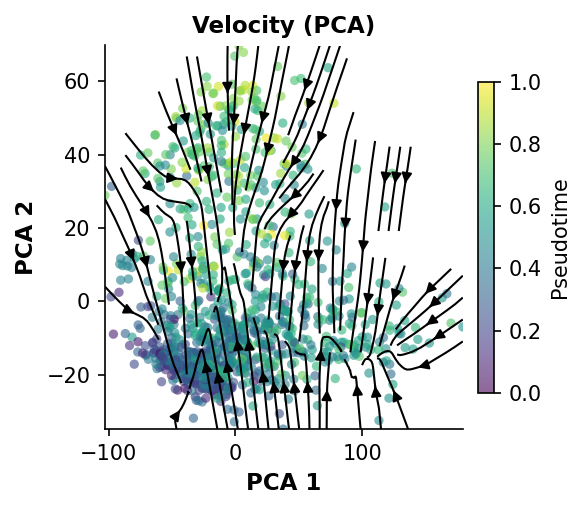

In [26]:
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from sklearn.neighbors import NearestNeighbors
from scipy.spatial import cKDTree
%matplotlib inline 
def plot_velocity_streams(X_2d, V_2d_smooth, pseudo_norm,
                          title="Velocity", mode_label="PCA"):
    """
    Identical plot logic to the working Decipher notebook's final plot.
    V_2d_smooth: (N, 2) already projected and smoothed.
    """
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['svg.fonttype'] = 'none'
 
    fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
    sc = ax.scatter(X_2d[:, 0], X_2d[:, 1],
                    c=pseudo_norm, cmap="viridis",
                    s=20, alpha=0.6, edgecolors='none', rasterized=True)
 
    density = 2; grid_n = int(60 * density)
    x_min, x_max = X_2d[:, 0].min(), X_2d[:, 0].max()
    y_min, y_max = X_2d[:, 1].min(), X_2d[:, 1].max()
    x_grid = np.linspace(x_min, x_max, grid_n)
    y_grid = np.linspace(y_min, y_max, grid_n)
    Xg, Yg = np.meshgrid(x_grid, y_grid)
    grid_points = np.c_[Xg.ravel(), Yg.ravel()]
 
    n_cells = min(3000, len(X_2d))
    cidx = np.random.choice(len(X_2d), n_cells, replace=False)
    nbrs = NearestNeighbors(n_neighbors=20).fit(X_2d[cidx])
    _, idx = nbrs.kneighbors(grid_points)
    V_grid = V_2d_smooth[cidx][idx].mean(axis=1)
 
    nbrs_cells = NearestNeighbors(n_neighbors=1).fit(X_2d)
    dist_to_cells, _ = nbrs_cells.kneighbors(grid_points)
    dist_to_cells = dist_to_cells.ravel()
    support_threshold = np.percentile(dist_to_cells, 40)
    support_mask  = dist_to_cells < support_threshold
    velocity_mask = np.linalg.norm(V_grid, axis=1) > np.percentile(
        np.linalg.norm(V_grid, axis=1), 35)
    final_mask = support_mask & velocity_mask
    if final_mask.sum() == 0:
        final_mask = np.ones(len(grid_points), dtype=bool)
 
    tree = cKDTree(grid_points[final_mask])
    _, nn = tree.query(np.c_[Xg.ravel(), Yg.ravel()], k=1)
    U = V_grid[final_mask][nn, 0].reshape(Xg.shape)
    W = V_grid[final_mask][nn, 1].reshape(Yg.shape)
    grid_dist, _ = nbrs_cells.kneighbors(np.c_[Xg.ravel(), Yg.ravel()])
    gm = grid_dist.ravel() < support_threshold
    U.ravel()[~gm] = 0.0; W.ravel()[~gm] = 0.0
    U = gaussian_filter(U, sigma=1.2)
    W = gaussian_filter(W, sigma=1.2)
 
    ax.streamplot(Xg, Yg, U, W, color="black", density=1.2,
                  linewidth=1, arrowsize=1, arrowstyle='-|>',
                  minlength=0.2, integration_direction='both', zorder=3)
 
    ax.set_xlabel(f"{mode_label} 1", fontsize=11, fontweight='bold')
    ax.set_ylabel(f"{mode_label} 2", fontsize=11, fontweight='bold')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.colorbar(sc, ax=ax, fraction=0.04, pad=0.04).set_label(
        "Pseudotime", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"{out_dir}/final_velocity_{EMBED_MODE}.png",
                dpi=150, bbox_inches='tight')
    plt.show()
 
 
# ── Run the final plot ────────────────────────────────────────────────────────
V_pred = np.load(f"{out_dir}/V_pred.npy")
 
if EMBED_MODE == "pca":
    V_2d_final = project_to_2d(V_snap, X_pca_2d, X, k=30, scale=10.0, adaptive_scale=True)
else:
    print("Projecting velocity to UMAP (may take ~1 min)...")
    V_2d_final = project_to_2d(V_snap, X_umap_2d, X, k=30, scale=10.0, adaptive_scale=True)
 
V_2d_smooth = smooth_velocity(V_2d_final, X_2d_vis)
 
plot_velocity_streams(X_2d_vis, V_2d_smooth, pseudo_norm,
                      title=f"Velocity ({mode_label})",
                      mode_label=mode_label)